<a href="https://colab.research.google.com/github/Devyani006/California_Housing_price_prediction/blob/main/Activity1_Multiple_Linear_Regression_California_Housing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Activity 1 – Multiple Linear Regression: Explaining and Forecasting House Values in California


**Name:** Devyani Dhokrat   
**Roll No.:** AD3146   
 **GitHub:**

**Dataset:** California Housing (1990 US Census, block-group level), 20,640 rows    
**Task:** predict `median_house_value` (USD) from neighbourhood characteristics.

In [1]:
import os, sys, platform, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn, statsmodels
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from scipy import stats
from IPython.display import display, Markdown

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42                      # one seed used everywhere -> reproducible results
np.random.seed(SEED)
os.makedirs("images", exist_ok=True)
os.makedirs("results", exist_ok=True)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
pd.options.display.float_format = "{:,.4f}".format

def savefig(name):
    plt.tight_layout()
    plt.savefig(f"images/{name}.png", bbox_inches="tight")
    plt.show()

print("Python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__, "| statsmodels", statsmodels.__version__,
      "| matplotlib", matplotlib.__version__, "| seaborn", sns.__version__)

Python 3.13.18 | numpy 2.4.6 | pandas 2.2.3 | scikit-learn 1.6.1 | statsmodels 0.15.0 | matplotlib 3.10.0 | seaborn 0.13.2


### 1. Source and data dictionary
* **Origin:** Pace, R. K. & Barry, R. (1997), *Sparse Spatial Autoregressions*, Statistics & Probability Letters 33(3) – based on the **1990 US Census**; originally distributed through the StatLib repository.
* **Copy used here:** the widely shared CSV from Aurélien Géron's open-source *handson-ml* repository: <https://github.com/ageron/handson-ml/tree/master/datasets/housing>.
* **File type / size:** CSV, 20,640 rows × 10 columns.
* **What is one row?** - One census **block group** (a neighbourhood of typically 600–3,000 people) – **not** one house and **not** one person. All values are aggregates, so no personal data is involved.

| Column | Meaning | Unit | Role |
|---|---|---|---|
| `longitude`, `latitude` | Location of the block group | degrees | feature |
| `housing_median_age` | Median age of houses | years | feature |
| `total_rooms` | Total rooms in the block group | count | feature |
| `total_bedrooms` | Total bedrooms in the block group | count | feature |
| `population` | People living in the block group | count | feature |
| `households` | Number of households | count | feature |
| `median_income` | Median household income | tens of thousands of USD (3.5 = $35,000) | feature |
| `median_house_value` | Median house value | USD | **target (y)** |
| `ocean_proximity` | Text category of closeness to the ocean | category | *not used* (Activity 1 asks for numerical inputs; kept for future work) |

There is no record-ID column, so nothing needs to be excluded for that reason.

In [2]:
raw_df = pd.read_csv("/content/housing.csv")
print("Shape (rows, columns):", raw_df.shape)
display(raw_df.head(8))
print("\nData types:")
print(raw_df.dtypes.to_string())

Shape (rows, columns): (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.2300,37.8800,41.0000,880.0000,129.0000,322.0000,126.0000,8.3252,"452,600.0000",NEAR BAY
1,-122.2200,37.8600,21.0000,"7,099.0000","1,106.0000","2,401.0000","1,138.0000",8.3014,"358,500.0000",NEAR BAY
2,-122.2400,37.8500,52.0000,"1,467.0000",190.0000,496.0000,177.0000,7.2574,"352,100.0000",NEAR BAY
3,-122.2500,37.8500,52.0000,"1,274.0000",235.0000,558.0000,219.0000,5.6431,"341,300.0000",NEAR BAY
4,-122.2500,37.8500,52.0000,"1,627.0000",280.0000,565.0000,259.0000,3.8462,"342,200.0000",NEAR BAY
5,-122.2500,37.8500,52.0000,919.0000,213.0000,413.0000,193.0000,4.0368,"269,700.0000",NEAR BAY
6,-122.2500,37.8400,52.0000,"2,535.0000",489.0000,"1,094.0000",514.0000,3.6591,"299,200.0000",NEAR BAY
7,-122.2500,37.8400,52.0000,"3,104.0000",687.0000,"1,157.0000",647.0000,3.1200,"241,400.0000",NEAR BAY



Data types:
longitude             float64
latitude              float64
housing_median_age    float64
total_rooms           float64
total_bedrooms        float64
population            float64
households            float64
median_income         float64
median_house_value    float64
ocean_proximity        object


In [3]:
print("Summary statistics :")
display(raw_df.describe().T[["count", "mean", "std", "min", "50%", "max"]])

Summary statistics :


,count,mean,std,min,50%,max
longitude,"20,640.0000",-119.5697,2.0035,-124.3500,-118.4900,-114.3100
latitude,"20,640.0000",35.6319,2.1360,32.5400,34.2600,41.9500
housing_median_age,"20,640.0000",28.6395,12.5856,1.0000,29.0000,52.0000
total_rooms,"20,640.0000","2,635.7631","2,181.6153",2.0000,"2,127.0000","39,320.0000"
total_bedrooms,"20,433.0000",537.8706,421.3851,1.0000,435.0000,"6,445.0000"
population,"20,640.0000","1,425.4767","1,132.4621",3.0000,"1,166.0000","35,682.0000"
households,"20,640.0000",499.5397,382.3298,1.0000,409.0000,"6,082.0000"
median_income,"20,640.0000",3.8707,1.8998,0.4999,3.5348,15.0001
median_house_value,"20,640.0000","206,855.8169","115,395.6159","14,999.0000","179,700.0000","500,001.0000"


### 2. Quality checks – missing values, duplicates, caps and outliers


Missing values per column:
total_bedrooms    207

Duplicate rows: 0

Mean house value, rows WITH missing total_bedrooms   : $206,007
Mean house value, rows WITHOUT missing total_bedrooms: $206,864

Rows where median_house_value is exactly 500,001 (the cap): 965
Rows where housing_median_age is exactly 52 (the cap)      : 1273
Rows where median_income is at its maximum (15.0001)       : 49


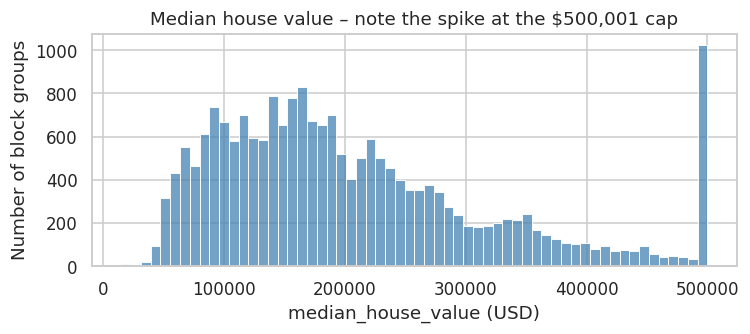

In [4]:
print("Missing values per column:")
print(raw_df.isna().sum()[lambda s: s > 0].to_string())
print("\nDuplicate rows:", raw_df.duplicated().sum())

# Is the missingness "random"? Compare the target for rows with / without missing total_bedrooms
miss = raw_df["total_bedrooms"].isna()
print(f"\nMean house value, rows WITH missing total_bedrooms   : ${raw_df.loc[miss, 'median_house_value'].mean():,.0f}")
print(f"Mean house value, rows WITHOUT missing total_bedrooms: ${raw_df.loc[~miss, 'median_house_value'].mean():,.0f}")

# Values that look like 'caps' (the survey stopped counting above a limit)
print("\nRows where median_house_value is exactly 500,001 (the cap):", (raw_df["median_house_value"] == 500001).sum())
print("Rows where housing_median_age is exactly 52 (the cap)      :", (raw_df["housing_median_age"] == 52).sum())
print("Rows where median_income is at its maximum (15.0001)       :", (raw_df["median_income"] == raw_df["median_income"].max()).sum())

fig, ax = plt.subplots(figsize=(7, 3.2))
sns.histplot(raw_df["median_house_value"], bins=60, ax=ax, color="steelblue")
ax.set_title("Median house value – note the spike at the $500,001 cap")
ax.set_xlabel("median_house_value (USD)"); ax.set_ylabel("Number of block groups")
savefig("01_target_cap_spike")

**Findings and decisions (also in the decision log):**
* `total_bedrooms` is missing in 207 rows (1.0%). The average house value in those rows is almost the same as elsewhere, so the missingness does not look systematic → drop these rows (alternative considered: median imputation; rejected because dropping 1% is simpler and cannot leak information).
* `median_house_value` is capped at \$500,001 – the real value is unknown but higher. If we keep these rows, the model learns that expensive areas are "only" \$500k, which flattens the slope and biases every coefficient → drop capped rows for model fitting, and state the limitation: *he model cannot be used for the most expensive neighbourhoods.
* `housing_median_age` (cap 52) and `median_income` (cap 15.0001) are also capped, but far fewer rows are affected and the *input* caps matter less → **kept**, noted as a limitation.
* There are no duplicates. Extreme `total_rooms` / `population` values belong to very large block groups (real, not typos) → kept.

In [5]:
n_raw = len(raw_df)
df = raw_df.dropna(subset=["total_bedrooms"]).copy()
n_after_missing = len(df)
df = df[df["median_house_value"] < 500001].copy()
n_after_cap = len(df)
print(f"Rows at start: {n_raw:,} | after dropping missing total_bedrooms: {n_after_missing:,} "
      f"(-{n_raw - n_after_missing}) | after dropping capped targets: {n_after_cap:,} (-{n_after_missing - n_after_cap})")

# Row-wise engineered features (no information from other rows, so no leakage).
# These "combine" overlapping count features into per-household ratios (used later for the multicollinearity fix).
df["rooms_per_household"]      = df["total_rooms"] / df["households"]
df["bedrooms_per_room"]        = df["total_bedrooms"] / df["total_rooms"]
df["people_per_household"]     = df["population"] / df["households"]

TARGET = "median_house_value"
RAW_FEATURES = ["median_income", "housing_median_age", "total_rooms", "total_bedrooms",
                "population", "households", "latitude", "longitude"]
REFINED_FEATURES = ["median_income", "housing_median_age", "rooms_per_household",
                    "bedrooms_per_room", "people_per_household", "latitude", "longitude"]

# 80:20 train/test split. From here on, ALL exploration and model decisions use the training set only.
train_df, test_df = train_test_split(df, test_size=0.20, random_state=SEED)
print(f"\nTraining rows: {len(train_df):,} | Test rows: {len(test_df):,}  (80:20 split, random_state={SEED})")

Rows at start: 20,640 | after dropping missing total_bedrooms: 20,433 (-207) | after dropping capped targets: 19,475 (-958)

Training rows: 15,580 | Test rows: 3,895  (80:20 split, random_state=42)


> **Note.** The train/test split is done here, right after cleaning, so the test set (20%) stays locked away while I explore, choose features and diagnose. All plots, correlations and VIFs below use the **training set only**. The test set is used only to report results. Where I *choose between* models, I will  use 5-fold cross-validation **inside the training set**.

## 3. Explore before modelling  

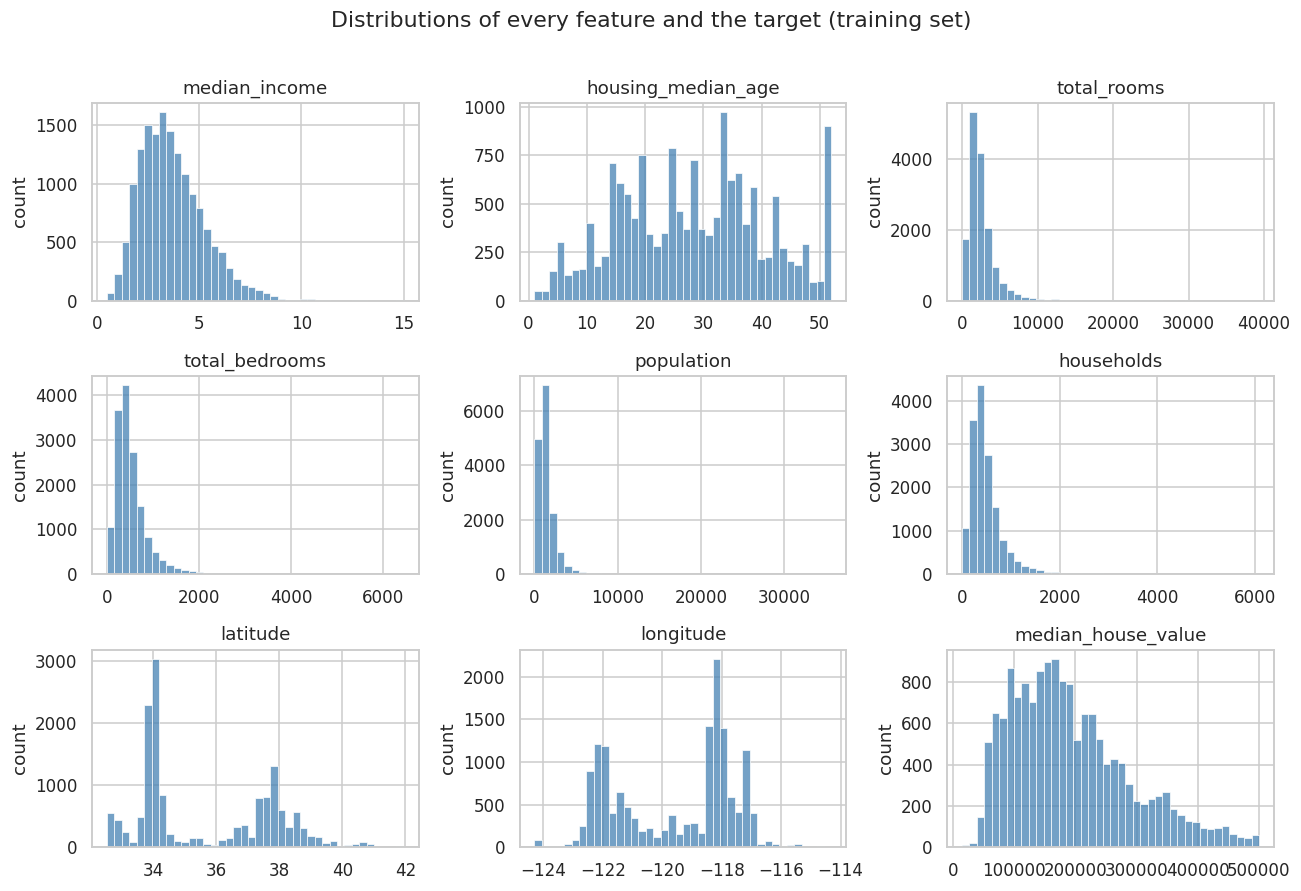

In [6]:
cols = RAW_FEATURES + [TARGET]
fig, axes = plt.subplots(3, 3, figsize=(12, 8))
for ax, c in zip(axes.ravel(), cols):
    sns.histplot(train_df[c], bins=40, ax=ax, color="steelblue")
    ax.set_title(c); ax.set_xlabel(""); ax.set_ylabel("count")
fig.suptitle("Distributions of every feature and the target (training set)", y=1.01)
savefig("02_distributions")

**Observation.** Income is roughly bell-shaped with a long right tail. The four count features (`total_rooms`, `total_bedrooms`, `population`, `households`) are all strongly right-skewed: most block groups are small, a few are huge. `housing_median_age` is spread fairly evenly but has a pile-up at 52 years (the cap). The target is right-skewed and its right edge is cut off at about $500k because capped rows were removed. Latitude and longitude each show two clear clusters (the Bay Area and the Los Angeles/San Diego region). **Implication:** the skewed count features may let a few giant block groups pull a straight line around, and location is clearly not a simple straight-line story.

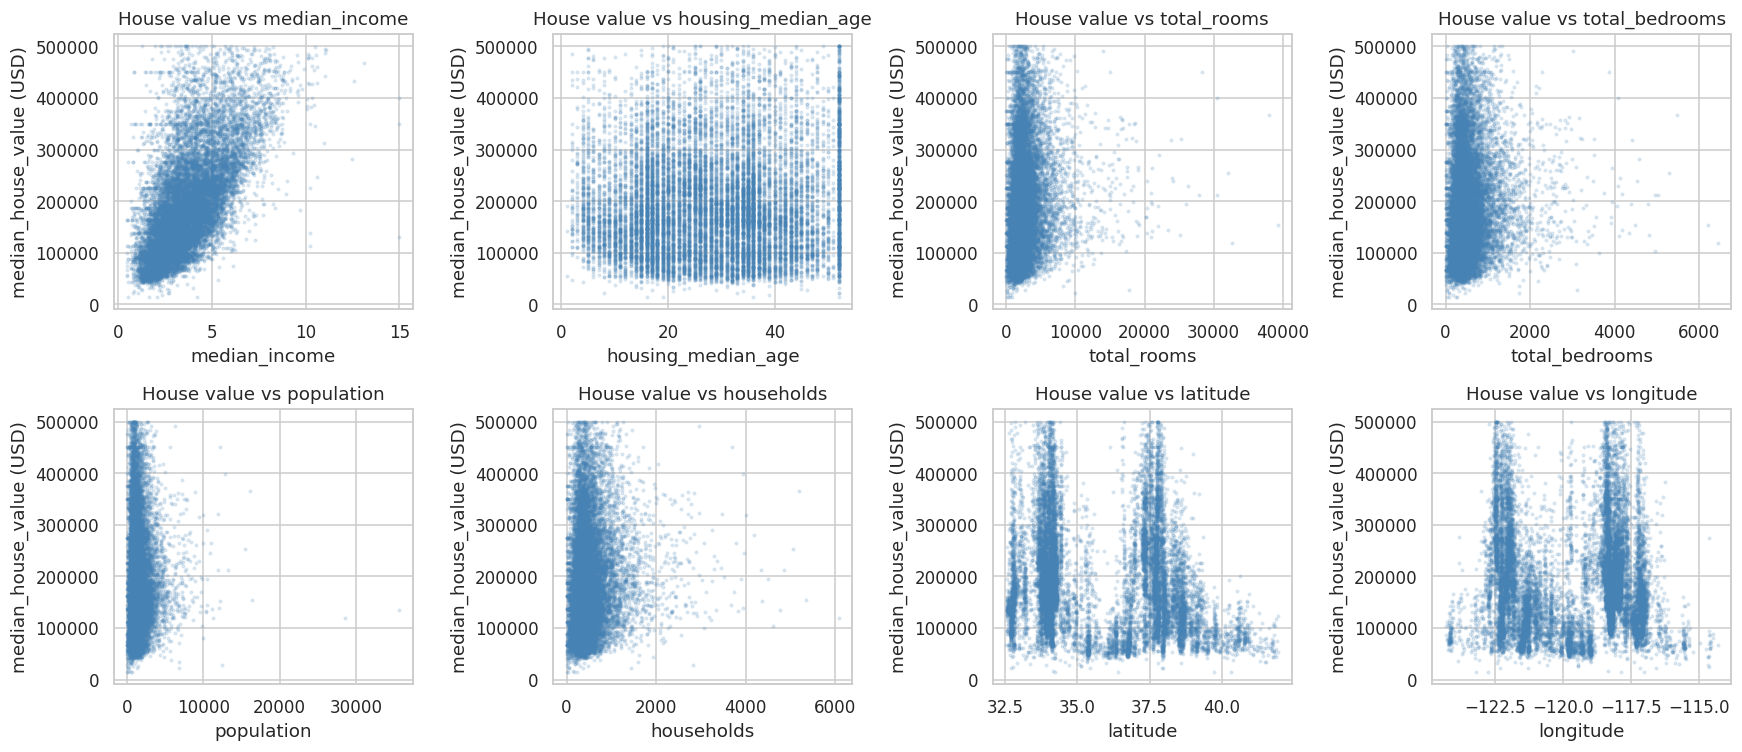

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.ravel(), RAW_FEATURES):
    ax.scatter(train_df[c], train_df[TARGET], s=3, alpha=0.15, color="steelblue")
    ax.set_title(f"House value vs {c}"); ax.set_xlabel(c); ax.set_ylabel("median_house_value (USD)")
savefig("03_scatter_target_vs_features")

**Observation.** Only `median_income` shows a clear upward, roughly straight-line relationship with house value (the cloud also fans out at higher incomes, so errors will be larger there). The room, bedroom, population and household counts show almost no visible pattern on their own. `housing_median_age` shows vertical stripes (it takes whole-year values) and no obvious trend. Latitude and longitude show several separate peaks – high values near the coast and in the two big metro areas – which a single straight line cannot follow. **Implication:** income should be the strongest single predictor, and a linear model will capture location only crudely.

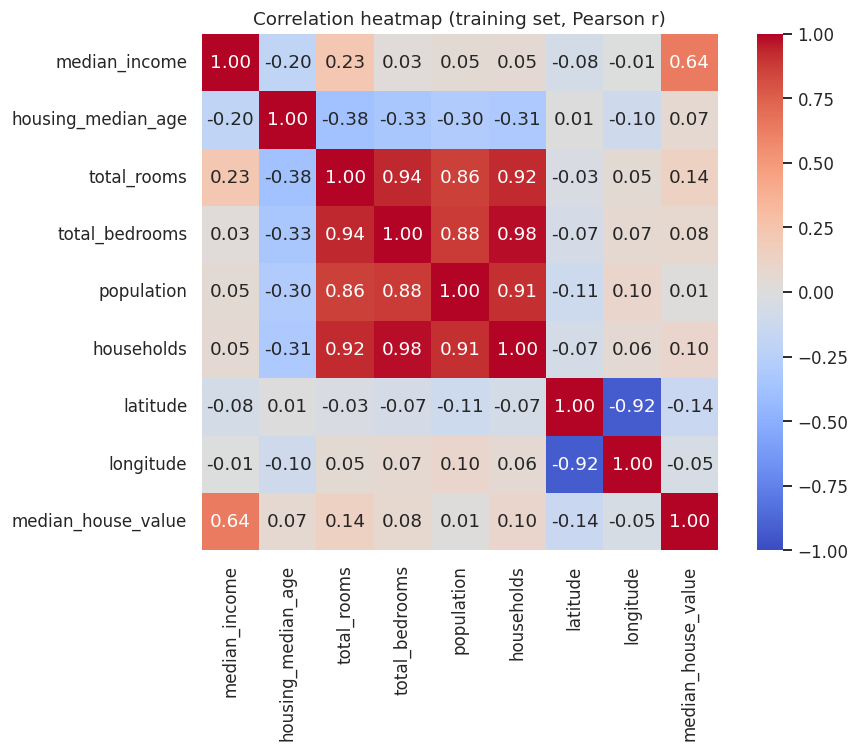

Correlation of each feature with the target (strongest first):
median_income         0.6390
latitude             -0.1440
total_rooms           0.1430
households            0.0960
total_bedrooms        0.0780
housing_median_age    0.0670
longitude            -0.0500
population            0.0130

Feature-feature pairs with |r| > 0.70 (possible multicollinearity):
  total_bedrooms       vs households            r = +0.979
  total_rooms          vs total_bedrooms        r = +0.936
  latitude             vs longitude             r = -0.924
  total_rooms          vs households            r = +0.924
  population           vs households            r = +0.911
  total_bedrooms       vs population            r = +0.881
  total_rooms          vs population            r = +0.861


In [8]:
corr = train_df[RAW_FEATURES + [TARGET]].corr()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax, square=True)
ax.set_title("Correlation heatmap (training set, Pearson r)")
savefig("04_correlation_heatmap")

print("Correlation of each feature with the target (strongest first):")
print(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3).to_string())

print("\nFeature-feature pairs with |r| > 0.70 (possible multicollinearity):")
pairs = [(a, b, corr.loc[a, b]) for i, a in enumerate(RAW_FEATURES) for b in RAW_FEATURES[i + 1:] if abs(corr.loc[a, b]) > 0.70]
for a, b, r in sorted(pairs, key=lambda t: -abs(t[2])):
    print(f"  {a:20s} vs {b:20s}  r = {r:+.3f}")

**Observation.** Feature → target: `median_income` has a strong positive correlation with house value (r ≈ +0.64). Every other feature is weak (|r| ≤ 0.15). Feature ↔ feature: the four count features are almost the same variable seen four times (e.g. `total_bedrooms` vs `households` r ≈ +0.98, `total_rooms` vs `total_bedrooms` r ≈ +0.94), and latitude and longitude are strongly negatively correlated (r ≈ −0.92) because California runs diagonally.  **Implication:** this data is a textbook case of possible **multicollinearity**, so I will check VIF and not trust individual coefficients blindly.

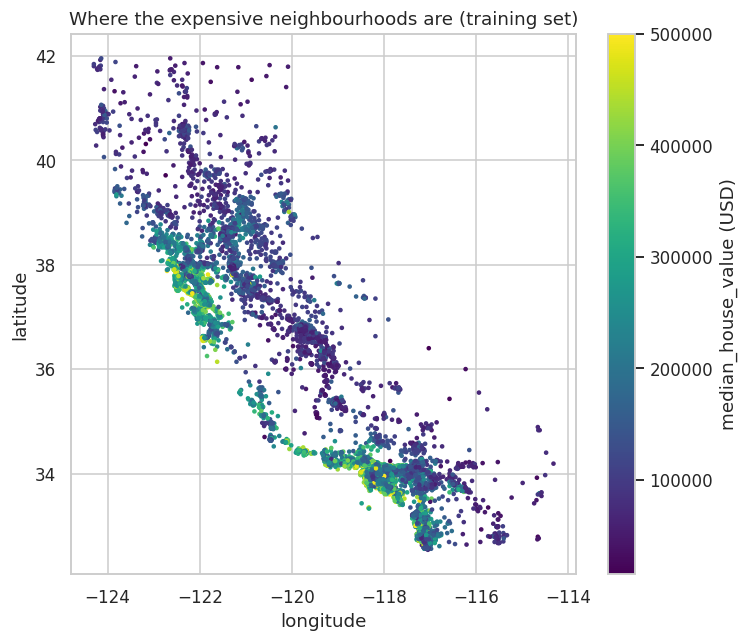

In [9]:
fig, ax = plt.subplots(figsize=(7, 6))
sc = ax.scatter(train_df["longitude"], train_df["latitude"], c=train_df[TARGET], s=4, cmap="viridis")
plt.colorbar(sc, label="median_house_value (USD)")
ax.set_title("Where the expensive neighbourhoods are (training set)")
ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
savefig("05_geographic_value_map")

**Observation.** The most expensive block groups (the brightest colours) hug the coast, especially the San Francisco Bay Area and the Los Angeles–Orange County–San Diego strip, while the inland Central Valley and the far north are cheaper. Location clearly matters a lot. A linear model with latitude and longitude as straight-line terms can only draw one tilted "slope" across this map, so I should expect regional mistakes.

## 4. Manual calculation worksheet  *(normal equations by hand)*  

I have taken **6 observations** from the training set and **two features** – `median_income` (X₁) and `housing_median_age` (X₂). To keep the numbers readable the target is expressed in **thousands of dollars** (`y_k = median_house_value / 1000`).

The least-squares coefficients solve the **normal equations**

$$(X^TX)\,b = X^Ty \quad\Rightarrow\quad b = (X^TX)^{-1}X^Ty, \qquad b=\begin{bmatrix}b_0\\b_1\\b_2\end{bmatrix}$$

where the first column of the design matrix $X$ is all ones (it carries the intercept $b_0$).

In [10]:
np.set_printoptions(suppress=True, precision=4, linewidth=140)

sample = train_df.sample(6, random_state=SEED)[["median_income", "housing_median_age", TARGET]].copy()
sample["y_k"] = sample[TARGET] / 1000
sample = sample.reset_index().rename(columns={"index": "row id"})
sample.insert(0, "obs", range(1, 7))
print("Step 12 – the 6 chosen observations:")
display(sample[["obs", "row id", "median_income", "housing_median_age", "y_k"]])

x1 = sample["median_income"].to_numpy()
x2 = sample["housing_median_age"].to_numpy()
y  = sample["y_k"].to_numpy()
n  = len(y)

X = np.column_stack([np.ones(n), x1, x2])
print("\nStep 13 – design matrix X (columns: 1, X1 = median_income, X2 = housing_median_age):")
print(X)
print("\ntarget vector y (thousand USD):")
print(y.reshape(-1, 1))

Step 12 – the 6 chosen observations:


,obs,row id,median_income,housing_median_age,y_k
0,1,10349,7.5488,25.0000,278.1000
1,2,9657,1.9732,32.0000,69.4000
2,3,7631,3.5094,11.0000,162.9000
3,4,1790,1.0521,40.0000,69.1000
4,5,4569,2.3438,42.0000,213.3000
5,6,8236,4.6629,25.0000,162.5000



Step 13 – design matrix X (columns: 1, X1 = median_income, X2 = housing_median_age):
[[ 1.      7.5488 25.    ]
 [ 1.      1.9732 32.    ]
 [ 1.      3.5094 11.    ]
 [ 1.      1.0521 40.    ]
 [ 1.      2.3438 42.    ]
 [ 1.      4.6629 25.    ]]

target vector y (thousand USD):
[[278.1]
 [ 69.4]
 [162.9]
 [ 69.1]
 [213.3]
 [162.5]]


In [11]:
# To Show where every entry of X^T X and X^T y comes from (the raw sums), then compute the matrices.
sums = {
    "n":        n,
    "Σx1":      x1.sum(),
    "Σx2":      x2.sum(),
    "Σx1²":     (x1**2).sum(),
    "Σx1·x2":   (x1*x2).sum(),
    "Σx2²":     (x2**2).sum(),
    "Σy":       y.sum(),
    "Σx1·y":    (x1*y).sum(),
    "Σx2·y":    (x2*y).sum(),
}
print("Intermediate sums:")
for k, v in sums.items():
    print(f"  {k:8s} = {v:,.4f}")

XtX = X.T @ X
Xty = X.T @ y
print("\nXᵀX  =  [[ n,    Σx1,    Σx2 ],\n         [ Σx1,  Σx1²,   Σx1x2],\n         [ Σx2,  Σx1x2,  Σx2² ]]")
print(XtX)
print("\nXᵀy  =  [Σy, Σx1·y, Σx2·y]ᵀ")
print(Xty.reshape(-1, 1))

# sanity check: matrix products equal the hand sums
assert np.allclose(XtX, [[n, sums["Σx1"], sums["Σx2"]],
                         [sums["Σx1"], sums["Σx1²"], sums["Σx1·x2"]],
                         [sums["Σx2"], sums["Σx1·x2"], sums["Σx2²"]]])
assert np.allclose(Xty, [sums["Σy"], sums["Σx1·y"], sums["Σx2·y"]])
print("\nCheck passed: the matrices match the hand-computed sums.")

Intermediate sums:
  n        = 6.0000
  Σx1      = 21.0902
  Σx2      = 175.0000
  Σx1²     = 101.5367
  Σx1·x2   = 547.5619
  Σx2²     = 5,759.0000
  Σy       = 955.3000
  Σx1·y    = 4,138.2965
  Σx2·y    = 26,750.3000

XᵀX  =  [[ n,    Σx1,    Σx2 ],
         [ Σx1,  Σx1²,   Σx1x2],
         [ Σx2,  Σx1x2,  Σx2² ]]
[[   6.       21.0902  175.    ]
 [  21.0902  101.5367  547.5619]
 [ 175.      547.5619 5759.    ]]

Xᵀy  =  [Σy, Σx1·y, Σx2·y]ᵀ
[[  955.3   ]
 [ 4138.2965]
 [26750.3   ]]

Check passed: the matrices match the hand-computed sums.


In [12]:
# Step 14 – solve (XᵀX) b = Xᵀy using the matrix inverse, showing each step
det = np.linalg.det(XtX)
XtX_inv = np.linalg.inv(XtX)
print(f"det(XᵀX) = {det:,.4f}   (non-zero, so the inverse exists and the solution is unique)")
print("\n(XᵀX)⁻¹ =")
print(XtX_inv)
print("\nCheck: (XᵀX)⁻¹ · XᵀX should be the identity matrix:")
print(np.round(XtX_inv @ XtX, 6))

print("\nb = (XᵀX)⁻¹ · Xᵀy, one row at a time:")
b = XtX_inv @ Xty
for i, name in enumerate(["b0 (intercept)", "b1 (median_income)", "b2 (housing_median_age)"]):
    terms = " + ".join(f"({XtX_inv[i, j]:.4f} × {Xty[j]:.4f})" for j in range(3))
    print(f"  {name:24s} = {terms} = {b[i]:.4f}")

# Cross-check with a linear solver (Gaussian elimination under the hood)
b_solve = np.linalg.solve(XtX, Xty)
print("\nCross-check with np.linalg.solve:", b_solve.round(4), "| same answer:", np.allclose(b, b_solve))

det(XᵀX) = 80,276.8780   (non-zero, so the inverse exists and the solution is unique)

(XᵀX)⁻¹ =
[[ 3.5493 -0.3193 -0.0775]
 [-0.3193  0.0489  0.0051]
 [-0.0775  0.0051  0.002 ]]

Check: (XᵀX)⁻¹ · XᵀX should be the identity matrix:
[[ 1.  0.  0.]
 [-0.  1. -0.]
 [-0. -0.  1.]]

b = (XᵀX)⁻¹ · Xᵀy, one row at a time:
  b0 (intercept)           = (3.5493 × 955.3000) + (-0.3193 × 4138.2965) + (-0.0775 × 26750.3000) = -3.7690
  b1 (median_income)       = (-0.3193 × 955.3000) + (0.0489 × 4138.2965) + (0.0051 × 26750.3000) = 32.5755
  b2 (housing_median_age)  = (-0.0775 × 955.3000) + (0.0051 × 4138.2965) + (0.0020 × 26750.3000) = 1.6622

Cross-check with np.linalg.solve: [-3.769  32.5755  1.6622] | same answer: True


In [13]:
# Step 15 – fitted equation, one prediction and its residual
b0, b1, b2 = b
print(f"Fitted equation (sample of 6):  y_k = {b0:.3f} + {b1:.3f}·median_income + {b2:.3f}·housing_median_age")
print("(y_k is in thousand USD)\n")

sample["y_hat_k"]   = X @ b
sample["residual_k"] = sample["y_k"] - sample["y_hat_k"]
display(sample[["obs", "median_income", "housing_median_age", "y_k", "y_hat_k", "residual_k"]])

o = sample.iloc[0]
print(f"Worked example – observation 1: ŷ = {b0:.3f} + {b1:.3f}×{o.median_income:.4f} + {b2:.3f}×{o.housing_median_age:.0f} = {o.y_hat_k:.3f}")
print(f"Actual y = {o.y_k:.3f}  →  residual = actual − predicted = {o.residual_k:.3f} (thousand USD)")
print(f"\nSum of residuals = {sample['residual_k'].sum():.6f}  (≈ 0 – a property of least squares with an intercept)")

# write the worksheet to a markdown file so it can be submitted as a typed worksheet(just an extra effort for the project)
def mat(M):
    return "\n".join("    " + "  ".join(f"{v:>14,.4f}" for v in row) for row in np.atleast_2d(M))
ws = f"""# Manual Calculation Worksheet – Activity 1 (typed)

Sample: 6 training observations, features X1 = median_income, X2 = housing_median_age, target y_k = median_house_value / 1000.

## Observations
{sample[['obs','row id','median_income','housing_median_age','y_k']].to_markdown(index=False)}

## Design matrix X (1, X1, X2)
{mat(X)}

## X^T X
{mat(XtX)}

## X^T y
{mat(Xty.reshape(-1,1))}

## det(X^T X) = {det:,.4f}

## (X^T X)^-1
{mat(XtX_inv)}

## Solution b = (X^T X)^-1 X^T y
b0 = {b0:.4f}, b1 = {b1:.4f}, b2 = {b2:.4f}

Fitted equation: y_k = {b0:.3f} + {b1:.3f}*median_income + {b2:.3f}*housing_median_age

## Worked prediction and residual (observation 1)
y_hat = {o.y_hat_k:.3f}, actual = {o.y_k:.3f}, residual = {o.residual_k:.3f}
"""
with open("manual_calculation_worksheet.md", "w", encoding="utf-8") as f:
    f.write(ws)
print("\nSaved: manual_calculation_worksheet.md")

Fitted equation (sample of 6):  y_k = -3.769 + 32.576·median_income + 1.662·housing_median_age
(y_k is in thousand USD)



,obs,median_income,housing_median_age,y_k,y_hat_k,residual_k
0,1,7.5488,25.0000,278.1000,283.6929,-5.5929
1,2,1.9732,32.0000,69.4000,113.7002,-44.3002
2,3,3.5094,11.0000,162.9000,128.8361,34.0639
3,4,1.0521,40.0000,69.1000,96.9927,-27.8927
4,5,2.3438,42.0000,213.3000,142.3949,70.9051
5,6,4.6629,25.0000,162.5000,189.6831,-27.1831


Worked example – observation 1: ŷ = -3.769 + 32.576×7.5488 + 1.662×25 = 283.693
Actual y = 278.100  →  residual = actual − predicted = -5.593 (thousand USD)

Sum of residuals = -0.000000  (≈ 0 – a property of least squares with an intercept)

Saved: manual_calculation_worksheet.md


**What the worksheet shows.** From 6 neighbourhoods the normal equations give b₀ ≈ −3.77, b₁ ≈ 32.58 and b₂ ≈ 1.66 (thousand USD). In words: in this tiny sample, each extra unit of income (+$10,000) goes with about +$32.6k in house value and each extra year of house age with about +$1.7k. Observation 1 is predicted at ≈ $283.7k against an actual $278.1k (residual ≈ −$5.6k). The residuals sum to zero, as least squares with an intercept guarantees. With only 6 points this is a demonstration of the mechanics, not a trustworthy estimate – for instance, observation 5 is off by about $71k.

## 5. Baseline and library models

### 5.1 Split details and scaling
The split was made in Section 2 (80:20, `random_state=42`). I will record it again, then explain scaling.

In [14]:
print(f"Total usable rows : {len(df):,}")
print(f"Training set      : {len(train_df):,} rows ({len(train_df)/len(df):.0%})")
print(f"Test set          : {len(test_df):,} rows ({len(test_df)/len(df):.0%})")

# Scaling: fit on TRAINING data only, then apply to test. OLS itself does not need scaling, but
# scaling lets us compare coefficient sizes on one common scale (standard deviations).
scaler = StandardScaler().fit(train_df[RAW_FEATURES])
X_train_s = scaler.transform(train_df[RAW_FEATURES])
print("\nScaler fitted on training data only. Training means after scaling ≈ 0:", np.round(X_train_s.mean(axis=0), 6))

Total usable rows : 19,475
Training set      : 15,580 rows (80%)
Test set          : 3,895 rows (20%)

Scaler fitted on training data only. Training means after scaling ≈ 0: [ 0. -0.  0.  0.  0.  0. -0. -0.]


**How scaling changes the meaning of a coefficient.** With raw features, a coefficient is "change in house value for **one raw unit** of the feature" (one extra room, one more year, $10,000 more income…). Units differ wildly, so raw coefficients cannot be compared. After standardising, a coefficient is "change in house value for a **one-standard-deviation** increase in the feature", so sizes become comparable (Section 6).

In [15]:
def adj_r2(r2, n, k):
    """Adjusted R² = 1 - (1 - R²)(n - 1)/(n - k - 1); k = number of features."""
    return 1 - (1 - r2) * (n - 1) / (n - k - 1)

def reg_metrics(y_true, y_pred, k):
    mse = mean_squared_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    return {"MAE": mean_absolute_error(y_true, y_pred), "MSE": mse, "RMSE": np.sqrt(mse),
            "R2": r2, "Adj_R2": adj_r2(r2, len(y_true), k)}

cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
y_train, y_test = train_df[TARGET], test_df[TARGET]
results = []

def fit_and_log(name, model, feats):
    """Fit on training data only; log train R², 5-fold CV R² (inside train) and test metrics."""
    model.fit(train_df[feats], y_train)
    k = len(feats)
    cv_r2 = cross_val_score(model, train_df[feats], y_train, cv=cv, scoring="r2").mean() if k > 0 else np.nan
    m = reg_metrics(y_test, model.predict(test_df[feats]), k)
    results.append({"Model": name, "Features": k, "Train R2": model.score(train_df[feats], y_train),
                    "CV R2 (train)": cv_r2, **{f"Test {a}": v for a, v in m.items()}})
    return model

# Baseline: always predict the training-set mean (DummyRegressor uses no features at all)
baseline = DummyRegressor(strategy="mean").fit(train_df[["median_income"]], y_train)
m = reg_metrics(y_test, baseline.predict(test_df[["median_income"]]), 0)
results.append({"Model": "Baseline: predict training mean", "Features": 0, "Train R2": 0.0, "CV R2 (train)": np.nan,
                **{f"Test {a}": v for a, v in m.items()}})
print(f"Baseline prediction for every neighbourhood: ${baseline.constant_[0][0]:,.0f}")

Baseline prediction for every neighbourhood: $192,150


### 5.2 Single-feature model (the feature most correlated with the target)

In [16]:
best_feature = corr[TARGET].drop(TARGET).abs().idxmax()
print("Most correlated feature with the target:", best_feature)

single = fit_and_log(f"Single feature ({best_feature})", LinearRegression(), [best_feature])
print(f"Intercept   b0 = {single.intercept_:,.2f} USD")
print(f"Coefficient b1 = {single.coef_[0]:,.2f} USD per +1 unit of {best_feature}")
print(f"Test R² = {results[-1]['Test R2']:.4f}")

Most correlated feature with the target: median_income
Intercept   b0 = 46,023.58 USD
Coefficient b1 = 39,774.63 USD per +1 unit of median_income
Test R² = 0.4303


### 5.3 Multiple linear regression (all 8 selected numeric features) – model **M1**

In [17]:
m1 = fit_and_log("M1: Multiple (8 raw features)", LinearRegression(), RAW_FEATURES)
print(f"Intercept b0 = {m1.intercept_:,.2f}\n")
coef_m1 = pd.Series(m1.coef_, index=RAW_FEATURES, name="coefficient (USD per +1 raw unit)")
display(coef_m1.to_frame())

Intercept b0 = -3,378,319.07



,coefficient (USD per +1 raw unit)
median_income,"39,816.4706"
housing_median_age,"1,016.0916"
total_rooms,-9.9775
total_bedrooms,111.8389
population,-30.5564
households,37.9867
latitude,"-39,044.3512"
longitude,"-39,963.8021"


### 5.4 Verify the hand calculation with a library (same 6 rows, same 2 features)

In [18]:
check = LinearRegression().fit(sample[["median_income", "housing_median_age"]], sample["y_k"])
cmp_df = pd.DataFrame({"By hand (normal equations)": b,
                       "Library (LinearRegression)": [check.intercept_, *check.coef_]},
                      index=["b0 (intercept)", "b1 (median_income)", "b2 (housing_median_age)"])
cmp_df["Absolute difference"] = (cmp_df.iloc[:, 0] - cmp_df.iloc[:, 1]).abs()
display(cmp_df)
print("Identical to numerical precision:", np.allclose(cmp_df.iloc[:, 0], cmp_df.iloc[:, 1]))

,By hand (normal equations),Library (LinearRegression),Absolute difference
b0 (intercept),-3.7690,-3.7690,0.0000
b1 (median_income),32.5755,32.5755,0.0000
b2 (housing_median_age),1.6622,1.6622,0.0000


Identical to numerical precision: True


**Comment (To understand):** the two columns agree to many decimal places (differences are of the order of 1e-12, i.e. floating-point rounding). That is expected, because scikit-learn solves the same least-squares problem – just with a numerically safer method (an orthogonal decomposition rather than an explicit matrix inverse). Note that with only 6 rows the sample coefficients are **not reliable estimates** – they are only used to understand the mechanics. The full-data coefficients (Section 5.3 / 6) are the ones to interpret.

## 6. Interpret the equation  

In [19]:
units = {
    "median_income":       ("+1 unit of income (= +$10,000 median household income)", ""),
    "housing_median_age":  ("+1 year of median house age", ""),
    "total_rooms":         ("+1 room in the block group", ""),
    "total_bedrooms":      ("+1 bedroom in the block group", ""),
    "population":          ("+1 person in the block group", ""),
    "households":          ("+1 household in the block group", ""),
    "latitude":            ("+1 degree north (≈ 111 km)", ""),
    "longitude":           ("+1 degree east (≈ 90 km at this latitude)", ""),
    "rooms_per_household":     ("+1 room per household", ""),
    "bedrooms_per_room":       ("+0.1 in the bedroom share (e.g. 20% → 30% of rooms are bedrooms)", ""),
    "people_per_household":    ("+1 person per household", ""),
}

def equation_string(model, feats):
    s = f"median_house_value = {model.intercept_:,.0f}"
    for f, c in zip(feats, model.coef_):
        s += f"\n      {c:+,.2f} × {f}"
    return s

print("Fitted equation for M1 (full training data):\n")
print("  " + equation_string(m1, RAW_FEATURES))
print("\nInterpretation, holding the other features constant:")
for f, c in zip(RAW_FEATURES, m1.coef_):
    print(f"  • {units[f][0]:<62s} → house value changes by {c:+,.0f} USD")

Fitted equation for M1 (full training data):

  median_house_value = -3,378,319
      +39,816.47 × median_income
      +1,016.09 × housing_median_age
      -9.98 × total_rooms
      +111.84 × total_bedrooms
      -30.56 × population
      +37.99 × households
      -39,044.35 × latitude
      -39,963.80 × longitude

Interpretation, holding the other features constant:
  • +1 unit of income (= +$10,000 median household income)         → house value changes by +39,816 USD
  • +1 year of median house age                                    → house value changes by +1,016 USD
  • +1 room in the block group                                     → house value changes by -10 USD
  • +1 bedroom in the block group                                  → house value changes by +112 USD
  • +1 person in the block group                                   → house value changes by -31 USD
  • +1 household in the block group                                → house value changes by +38 USD
  • +1 degree north (≈

**Reading M1's coefficients – and why to be suspicious of them.** Income behaves sensibly: (+$10,000) of median income goes with roughly +\$39.8k of house value, holding the others fixed. But several coefficients look odd: `total_rooms` is **negative** (≈ −\$10 per room) although its simple correlation with value is *positive*, and `population` is negative while `total_bedrooms` and `households` are positive. These sign flips are a classic symptom of multicollinearity: the four size features overlap so much that the model splits their shared effect between them in an unstable way. "Holding the other features constant" is also unrealistic here – you cannot add a room to a block group without changing its bedrooms and households. Latitude and longitude also have large coefficients that must be read as a *pair* (a tilted location surface), not one at a time.

,USD change per +1 standard deviation
latitude,"-83,922.2472"
longitude,"-80,144.8374"
median_income,"62,407.3907"
total_bedrooms,"47,792.9176"
population,"-35,625.5237"
total_rooms,"-22,255.2147"
households,"14,712.3427"
housing_median_age,"12,707.3933"


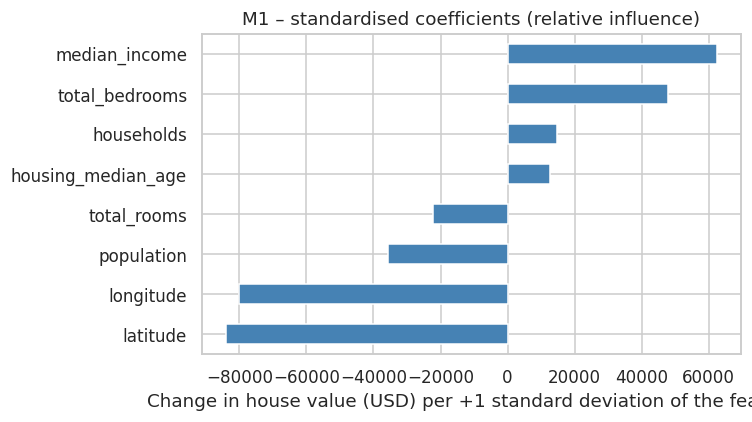

In [20]:
# Standardised coefficients: fit the same model on standardised features (scaler fitted on training data only)
m1_std = LinearRegression().fit(X_train_s, y_train)
std_coef = pd.Series(m1_std.coef_, index=RAW_FEATURES).sort_values(key=abs, ascending=False)
display(std_coef.to_frame("USD change per +1 standard deviation"))

fig, ax = plt.subplots(figsize=(7, 4))
std_coef.sort_values().plot(kind="barh", ax=ax, color="steelblue")
ax.set_title("M1 – standardised coefficients (relative influence)")
ax.set_xlabel("Change in house value (USD) per +1 standard deviation of the feature")
savefig("06_m1_standardised_coefficients")

**Which features matter most?** On a common scale, the two location terms and income carry the largest effects: +1 standard deviation of income goes with roughly +\$62k, while moving one standard deviation north or east goes with roughly (-\$80k to -\$84k). (Raw coefficients cannot show this because their units differ.) The size features come next, but their ranking and even their signs are shaky because of multicollinearity. This ranking describes **association in this model**, not proven cause; it also depends on the other features included.

**The intercept.** The intercept is the predicted value when *every* feature is zero – including latitude = 0° and longitude = 0° (a point in the Atlantic Ocean off Africa), income = 0 and zero households. No block group in the data looks like that, so the intercept is a **mathematical anchor of the line, not a meaningful price**. Do not interpret it.

## 7. Generate and compare predictions on the test set
Only test-set rows are shown below (never training predictions presented as test results).

In [21]:
pred_m1_test = m1.predict(test_df[RAW_FEATURES])
cmp_pred = pd.DataFrame({"actual (USD)": y_test.values, "predicted M1 (USD)": pred_m1_test}, index=test_df.index)
cmp_pred["error = actual − predicted"] = cmp_pred["actual (USD)"] - cmp_pred["predicted M1 (USD)"]
cmp_pred["abs % error"] = 100 * cmp_pred["error = actual − predicted"].abs() / cmp_pred["actual (USD)"]
print("Random sample of 10 test neighbourhoods:")
display(cmp_pred.sample(10, random_state=SEED).round(0))

print(f"\nNegative (impossible) predicted values on the test set with M1: {(pred_m1_test < 0).sum()} of {len(pred_m1_test)}")
print("\nThe 5 largest under-predictions and 5 largest over-predictions on the test set:")
display(pd.concat([cmp_pred.nlargest(5, "error = actual − predicted"),
                   cmp_pred.nsmallest(5, "error = actual − predicted")]).round(0))

Random sample of 10 test neighbourhoods:


,actual (USD),predicted M1 (USD),error = actual − predicted,abs % error
15875,"229,000.0000","196,074.0000","32,926.0000",14.0000
1307,"145,900.0000","204,612.0000","-58,712.0000",40.0000
388,"224,200.0000","231,694.0000","-7,494.0000",3.0000
4363,"423,700.0000","318,773.0000","104,927.0000",25.0000
14887,"158,600.0000","188,438.0000","-29,838.0000",19.0000
10546,"344,900.0000","323,241.0000","21,659.0000",6.0000
10815,"381,500.0000","291,080.0000","90,420.0000",24.0000
15542,"347,300.0000","366,598.0000","-19,298.0000",6.0000
19321,"136,900.0000","219,197.0000","-82,297.0000",60.0000
10429,"249,400.0000","200,329.0000","49,071.0000",20.0000



Negative (impossible) predicted values on the test set with M1: 13 of 3895

The 5 largest under-predictions and 5 largest over-predictions on the test set:


,actual (USD),predicted M1 (USD),error = actual − predicted,abs % error
20527,"310,000.0000","-28,515.0000","338,515.0000",109.0000
13360,"416,700.0000","86,182.0000","330,518.0000",79.0000
15856,"450,000.0000","153,523.0000","296,477.0000",66.0000
489,"489,600.0000","202,092.0000","287,508.0000",59.0000
4093,"375,000.0000","88,606.0000","286,394.0000",76.0000
11912,"112,500.0000","518,152.0000","-405,652.0000",361.0000
4548,"67,500.0000","371,116.0000","-303,616.0000",450.0000
14805,"187,500.0000","431,446.0000","-243,946.0000",130.0000
5540,"283,200.0000","490,189.0000","-206,989.0000",73.0000
8986,"228,300.0000","409,309.0000","-181,009.0000",79.0000


**Observation.** Many typical neighbourhoods are predicted within roughly 5–25% of the actual value, but some are off by 40–60%. The biggest errors are in both directions: the model badly under-predicts a few expensive neighbourhoods (actual $310k–$490k, predicted far lower) and badly over-predicts a few cheap ones. The largest under-prediction is a case where the model predicts a **negative** house value, which is impossible – a reminder that a straight line does not know that prices cannot go below zero. These outliers suggest that something not in this features (for example very specific local location effects) drives the price.

## 8. Evaluate the model  



In [22]:
res = pd.DataFrame(results).set_index("Model")
display(res[["Features", "Train R2", "CV R2 (train)", "Test MAE", "Test MSE", "Test RMSE", "Test R2", "Test Adj_R2"]]
        .style.format({"Train R2": "{:.4f}", "CV R2 (train)": "{:.4f}", "Test MAE": "{:,.0f}", "Test MSE": "{:,.0f}",
                       "Test RMSE": "{:,.0f}", "Test R2": "{:.4f}", "Test Adj_R2": "{:.4f}"}))

,Features,Train R2,CV R2 (train),Test MAE,Test MSE,Test RMSE,Test R2,Test Adj_R2
Model,,,,,,,,
Baseline: predict training mean,0,0.0000,nan,"79,594","9,687,231,282","98,424",-0.0002,-0.0002
Single feature (median_income),1,0.4087,0.4084,"56,826","5,517,550,383","74,280",0.4303,0.4302
M1: Multiple (8 raw features),8,0.5982,0.5953,"45,916","3,822,074,566","61,823",0.6054,0.6046


**Interpretation (test set, unseen data).**
* **Baseline** (predict the training mean ≈ \$192k for everyone): RMSE ≈ \$98.4k, R² ≈ 0 – exactly what a "no-skill" benchmark should give.
* **Single feature (income):** RMSE ≈ \$74.3k, MAE ≈ \$56.8k, R² ≈ 0.43. Income alone already explains about 43% of the variation – a big improvement over the mean.
* **M1 (8 features):** RMSE ≈ \$61.8k, MAE ≈ \$45.9k, R² ≈ 0.605, adjusted R² ≈ 0.605. Adding the other 7 features cuts the typical error by roughly \$12.5k (RMSE) and lifts R² by about 0.175. The adjusted R² is almost identical to R², which means the extra features are not just noise – they genuinely help on unseen data.
* **Is the added complexity worth it?** Yes for accuracy. Training R² (0.598) and 5-fold CV R² (0.595) are close to test R² (0.605), so there is no sign of overfitting; this simple linear model is, if anything, limited by being too simple (under-fitting), not by memorising.
* **In plain/simple words:** a typical prediction is off by about \$46k on average (MAE) or \$62k when big misses are weighted more (RMSE), against an average house value of about $192k. That is useful for ranking and screening neighbourhoods, but not precise enough to price a specific property.

## 9. Residual analysis, multicollinearity and assumptions (diagnose and iterate)
Residual = actual − predicted, computed on the **test** set.

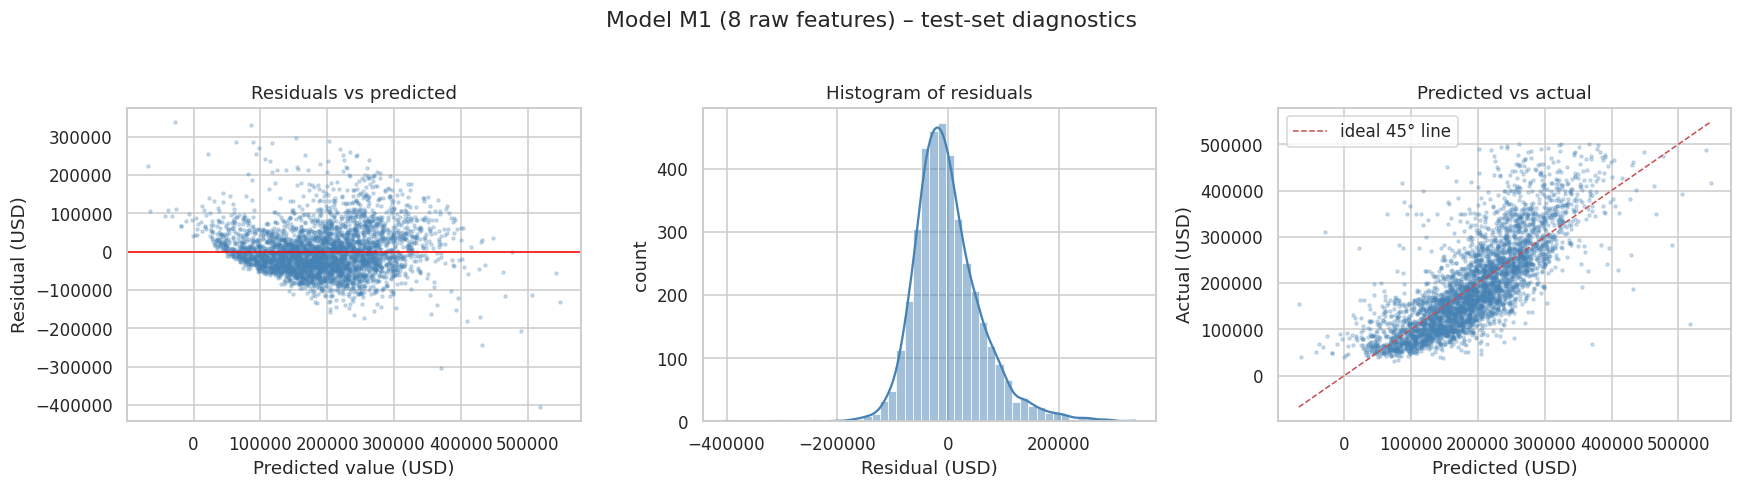

Residual mean = 603 | std = 61,820 | skewness = 0.89 | excess kurtosis = 2.83


In [23]:
def diag_plots(y_true, y_pred, title, fname):
    resid = np.asarray(y_true) - np.asarray(y_pred)
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
    axes[0].scatter(y_pred, resid, s=4, alpha=0.25, color="steelblue")
    axes[0].axhline(0, color="red", lw=1)
    axes[0].set_title("Residuals vs predicted"); axes[0].set_xlabel("Predicted value (USD)"); axes[0].set_ylabel("Residual (USD)")
    sns.histplot(resid, bins=50, kde=True, ax=axes[1], color="steelblue")
    axes[1].set_title("Histogram of residuals"); axes[1].set_xlabel("Residual (USD)"); axes[1].set_ylabel("count")
    axes[2].scatter(y_pred, y_true, s=4, alpha=0.25, color="steelblue")
    lim = [min(np.min(y_pred), np.min(y_true)), max(np.max(y_pred), np.max(y_true))]
    axes[2].plot(lim, lim, "r--", lw=1, label="ideal 45° line")
    axes[2].set_title("Predicted vs actual"); axes[2].set_xlabel("Predicted (USD)"); axes[2].set_ylabel("Actual (USD)"); axes[2].legend()
    fig.suptitle(title, y=1.03)
    savefig(fname)
    print(f"Residual mean = {resid.mean():,.0f} | std = {resid.std():,.0f} | skewness = {stats.skew(resid):.2f} | excess kurtosis = {stats.kurtosis(resid):.2f}")

diag_plots(y_test, pred_m1_test, "Model M1 (8 raw features) – test-set diagnostics", "07_m1_residual_diagnostics")

**Observation (M1).** The predicted-versus-actual cloud follows the 45° line loosely in the middle but bends away at both ends: cheap neighbourhoods are over-predicted and expensive ones under-predicted. The residual histogram is peaked near zero but **right-skewed** (skewness ≈ 0.9) with heavy tails (excess kurtosis ≈ 2.8), so there are more large positive misses than a normal curve would allow. The residuals-versus-predicted plot is not a flat random band: it is curved (residuals tend to be positive for the lowest and highest predictions and negative in the middle), which points to non-linearity, and the spread is wider for higher predicted values. A few predictions fall below zero. So next I will check why.

In [24]:
def vif_table(feats):
    Xc = sm.add_constant(train_df[feats])
    return pd.Series({f: variance_inflation_factor(Xc.values, i + 1) for i, f in enumerate(feats)}, name="VIF").sort_values(ascending=False)

vif_m1 = vif_table(RAW_FEATURES)
display(vif_m1.to_frame())
print("Rule of thumb: VIF > 5 = worth a look, VIF > 10 = serious. (VIF = 1 / (1 − R²) when this feature is predicted from all the others.)")

,VIF
total_bedrooms,36.9690
households,34.8714
total_rooms,14.1791
latitude,8.8884
longitude,8.7354
population,6.5755
median_income,1.8031
housing_median_age,1.3057


Rule of thumb: VIF > 5 = worth a look, VIF > 10 = serious. (VIF = 1 / (1 − R²) when this feature is predicted from all the others.)


**Observation.** `total_bedrooms` (VIF ≈ 37) and `households` (≈ 35) are far above the "serious" threshold of 10, and `total_rooms` (≈ 14) also exceeds it. VIF ≈ 37 means that 1 − 1/37 ≈ 97% of the variation in `total_bedrooms` can be predicted from the other features – it is almost redundant. Latitude and longitude (≈ 9) and population (≈ 6.6) are borderline. Income and house age are fine (< 2). This confirms the suspicion from the correlation heatmap and explains the sign flips in M1's coefficients. **What to do:** drop or combine the redundant features. I will simply **combine** them into ratios (below).

### 9.1 Fixing the redundancy: combine the overlapping count features  →  model M2
`total_rooms`, `total_bedrooms`, `population` and `households` all mostly measure how big the block group is. Rather than dropping information, I will combine them into three size-independent ratios that describe the character of the neighbourhood:

* `rooms_per_household` = total_rooms / households (spaciousness)
* `bedrooms_per_room` = total_bedrooms / total_rooms (share of rooms that are bedrooms – a proxy for flats vs. family homes)
* `people_per_household` = population / households (crowding)

I will keep `median_income`, `housing_median_age`, `latitude` and `longitude`. Because I am choosing between M1 and M2, compare them with cross-validation on the training set (not the test set).

In [25]:
vif_m2 = vif_table(REFINED_FEATURES)
m2 = fit_and_log("M2: Multiple (7 refined features)", LinearRegression(), REFINED_FEATURES)

both = pd.concat([vif_m1.rename("M1 VIF"), vif_m2.rename("M2 VIF")], axis=1)
display(both.fillna(float("nan")))
print(f"Largest VIF: M1 = {vif_m1.max():.1f}  →  M2 = {vif_m2.max():.1f}")

res = pd.DataFrame(results).set_index("Model")
display(res[["Features", "Train R2", "CV R2 (train)", "Test MAE", "Test RMSE", "Test R2", "Test Adj_R2"]]
        .style.format({"Train R2": "{:.4f}", "CV R2 (train)": "{:.4f}", "Test MAE": "{:,.0f}",
                       "Test RMSE": "{:,.0f}", "Test R2": "{:.4f}", "Test Adj_R2": "{:.4f}"}))
res.to_csv("results/model_comparison.csv")

,M1 VIF,M2 VIF
total_bedrooms,36.9690,NaN
households,34.8714,NaN
total_rooms,14.1791,NaN
latitude,8.8884,9.3817
longitude,8.7354,9.0112
population,6.5755,NaN
median_income,1.8031,2.0988
housing_median_age,1.3057,1.1553
bedrooms_per_room,NaN,1.9633
rooms_per_household,NaN,1.3078


Largest VIF: M1 = 37.0  →  M2 = 9.4


,Features,Train R2,CV R2 (train),Test MAE,Test RMSE,Test R2,Test Adj_R2
Model,,,,,,,
Baseline: predict training mean,0,0.0000,nan,"79,594","98,424",-0.0002,-0.0002
Single feature (median_income),1,0.4087,0.4084,"56,826","74,280",0.4303,0.4302
M1: Multiple (8 raw features),8,0.5982,0.5953,"45,916","61,823",0.6054,0.6046
M2: Multiple (7 refined features),7,0.5778,0.5763,"46,859","62,950",0.5908,0.5901


**Observation.** M2 brings the largest VIF down from about 37 to about 9.4 (latitude/longitude are still the highest – they jointly describe location – but all are under 10). The cost is a small loss in accuracy: test RMSE rises from ≈ $61.8k (M1) to ≈ $63.0k (M2), and test R² falls from 0.605 to 0.591 (CV R² on training data tells the same story: 0.595 → 0.576). So I can say, multicollinearity hurt the interpretation, not the prediction: M1 predicts slightly better, but M2's coefficients are stable and readable. Both are far better than the single-feature model (R² 0.43) and the mean baseline.

In [26]:
print("Final equation – model M2 (full training data):\n")
print("  " + equation_string(m2, REFINED_FEATURES))
print("\nInterpretation, holding the other features constant:")
for f, c in zip(REFINED_FEATURES, m2.coef_):
    c_show = c * 0.1 if f == "bedrooms_per_room" else c      # per +0.1 so the number is readable
    print(f"  • {units[f][0]:<75s} → {c_show:+,.0f} USD")

scaler2 = StandardScaler().fit(train_df[REFINED_FEATURES])
std2 = pd.Series(LinearRegression().fit(scaler2.transform(train_df[REFINED_FEATURES]), y_train).coef_,
                 index=REFINED_FEATURES).sort_values(key=abs, ascending=False)
display(std2.to_frame("M2 – USD per +1 standard deviation"))

Final equation – model M2 (full training data):

  median_house_value = -3,441,208
      +43,921.68 × median_income
      +822.92 × housing_median_age
      +2,506.64 × rooms_per_household
      +360,266.20 × bedrooms_per_room
      -358.88 × people_per_household
      -36,961.83 × latitude
      -39,113.84 × longitude

Interpretation, holding the other features constant:
  • +1 unit of income (= +$10,000 median household income)                      → +43,922 USD
  • +1 year of median house age                                                 → +823 USD
  • +1 room per household                                                       → +2,507 USD
  • +0.1 in the bedroom share (e.g. 20% → 30% of rooms are bedrooms)            → +36,027 USD
  • +1 person per household                                                     → -359 USD
  • +1 degree north (≈ 111 km)                                                  → -36,962 USD
  • +1 degree east (≈ 90 km at this latitude)                       

,M2 – USD per +1 standard deviation
latitude,"-79,446.0670"
longitude,"-78,440.3017"
median_income,"68,841.8013"
bedrooms_per_room,"20,492.3088"
housing_median_age,"10,291.6135"
rooms_per_household,"6,051.0263"
people_per_household,"-3,917.1117"


**Reading M2's coefficients (holding the others constant).**
* **Income:** +\$10,000 median income goes with about +\$43.9k house value – more stable than in M1 and the largest non-location effect.
* **House age:** each extra year goes with about +\$0.8k (older areas are slightly pricier in this model; effect is small).
* **Rooms per household:** one more room per household goes with about +\$2.5k – a small effect once income and location are accounted for.
* **People per household:** one more person per household goes with about −\$0.4k – a small crowding penalty.
* **Bedroom share:** a 10-point higher share of bedrooms goes with about +\$36k. Note : the sign is the opposite of its simple correlation with value (−0.22): once income and location are held fixed the relationship flips, which shows how conditional "holding others constant" statements are. .
* **Latitude / longitude:** about −\$37k per degree north and −\$39k per degree east – a tilted "coast-is-expensive" surface, to be read as a pair.
* **Intercept ≈ −$3.4 million:** meaningless on its own (it corresponds to latitude 0°, longitude 0°).

On a common scale (standardised), location and income dominate; ratios contribute much less.

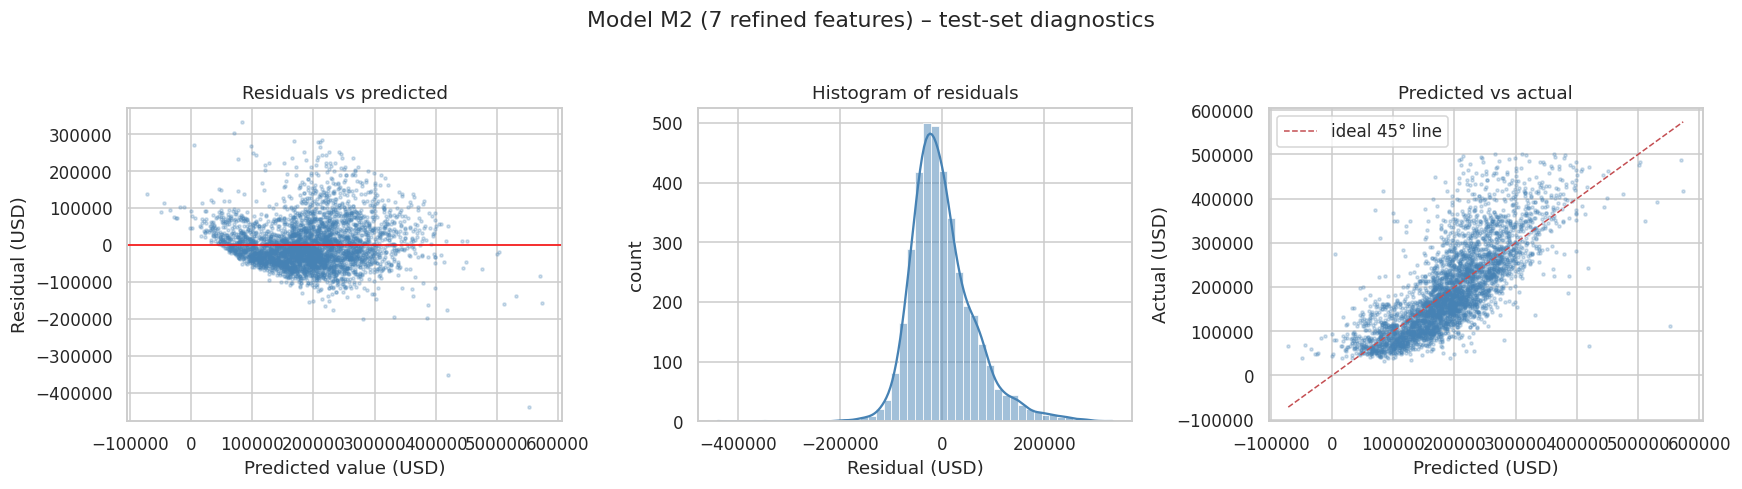

Residual mean = 1,126 | std = 62,940 | skewness = 0.87 | excess kurtosis = 2.77
Negative (impossible) predicted values on the test set with M2: 10 of 3895


,n,mean_actual,mean_residual,mean_abs_residual
band,,,,
cheapest 20%,781,"77,771.0000","-30,211.0000","41,487.0000"
20–40%,779,"129,380.0000","-28,336.0000","42,740.0000"
40–60%,778,"174,923.0000","-17,241.0000","34,188.0000"
60–80%,779,"236,982.0000","7,496.0000","34,065.0000"
most expensive 20%,778,"349,525.0000","74,075.0000","81,856.0000"


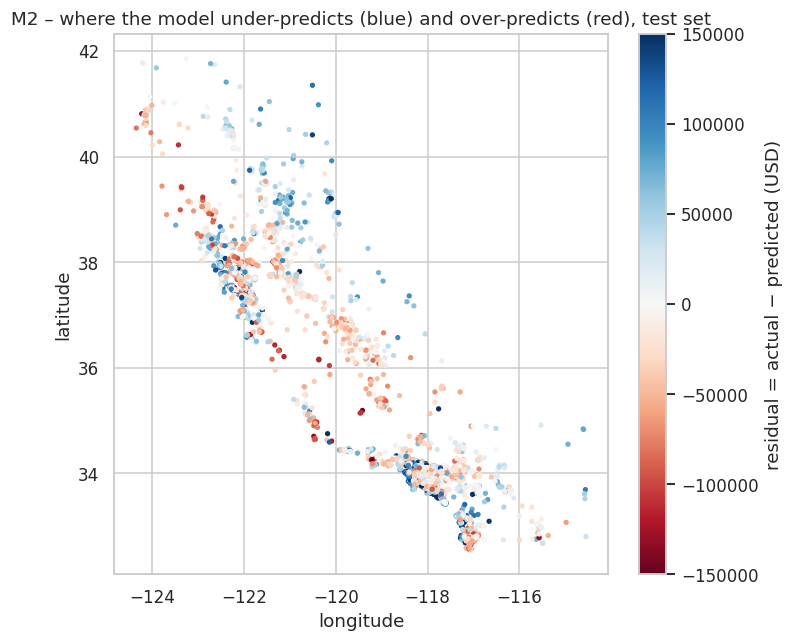

In [27]:
pred_m2_test = m2.predict(test_df[REFINED_FEATURES])
diag_plots(y_test, pred_m2_test, "Model M2 (7 refined features) – test-set diagnostics", "08_m2_residual_diagnostics")
print(f"Negative (impossible) predicted values on the test set with M2: {(pred_m2_test < 0).sum()} of {len(pred_m2_test)}")

# Where does M2 fail?  1) by price band   2) on a map
bands = pd.qcut(y_test, 5, labels=["cheapest 20%", "20–40%", "40–60%", "60–80%", "most expensive 20%"])
band_tbl = pd.DataFrame({"actual": y_test, "resid": y_test - pred_m2_test, "band": bands}).groupby("band", observed=True).agg(
    n=("resid", "size"), mean_actual=("actual", "mean"), mean_residual=("resid", "mean"), mean_abs_residual=("resid", lambda r: r.abs().mean()))
display(band_tbl.round(0))

fig, ax = plt.subplots(figsize=(7, 6))
sc = ax.scatter(test_df["longitude"], test_df["latitude"], c=(y_test - pred_m2_test), s=6, cmap="RdBu", vmin=-150000, vmax=150000)
plt.colorbar(sc, label="residual = actual − predicted (USD)")
ax.set_title("M2 – where the model under-predicts (blue) and over-predicts (red), test set")
ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
savefig("09_m2_residual_map")

**Observation (M2).**
* **Shape:** residuals are centred near zero (mean ≈ +\$1.1k) but right-skewed (skewness ≈ 0.9, excess kurtosis ≈ 2.8). The diagonal upper edge in the residual plot comes from the cap: no actual value exceeds \$500k, so residuals cannot exceed (500,000 − predicted).
* **Systematic bias by price band:** cheapest 20% are over-predicted by about \$30k on average and the most expensive 20% under-predicted by about \$74k (mean absolute error ≈ \$82k there, twice that of the middle bands). The model "pulls everything toward the middle" – typical for a straight line that lacks the features that make some neighbourhoods very expensive.
* **Geography:** the map shows clustered patches of the same colour – over-prediction (red) along parts of the Central Valley and some coastal strips, under-prediction (blue) in pockets of the Bay Area and Los Angeles. Neighbouring errors are not independent: the model misses local location effects.
* **Impossible values:** 10 of the 3,895 test predictions are negative (13 for M1) – a straight line does not know that prices cannot go below zero.

In [28]:
# Constant-variance check (Breusch–Pagan): small p-value = residual spread changes with the fitted value
ols = sm.OLS(y_train, sm.add_constant(train_df[REFINED_FEATURES])).fit()
bp_stat, bp_p, _, _ = het_breuschpagan(ols.resid, ols.model.exog)
print(f"Breusch–Pagan test on training residuals (M2): statistic = {bp_stat:.1f}, p-value = {bp_p:.2e}")
print("Shapiro-style normality is not meaningful at this sample size; we judge normality from the histogram and the kurtosis above.")

Breusch–Pagan test on training residuals (M2): statistic = 831.7, p-value = 2.69e-175
Shapiro-style normality is not meaningful at this sample size; we judge normality from the histogram and the kurtosis above.


### 9.2 Assumptions of linear regression – which look reasonable and which look doubtful?

| Assumption | Verdict for M2 | Evidence |
|---|---|---|
| **Linearity**  |  **Doubtful** | Income looks roughly linear, but latitude/longitude clearly are not (several peaks in the scatter plots). The residual map shows regional patches, and the model over-predicts cheap and under-predicts expensive areas. |
| **Independence of errors** |  **Doubtful** | Rows are neighbourhoods; nearby neighbourhoods have similar errors (clusters of one colour on the residual map). Errors are spatially correlated, so standard errors and p-values would be too optimistic. |
| **Constant variance of errors** (homoscedasticity) | **Doubtful** | The residual spread is not constant (wider for higher predicted values); the Breusch–Pagan test rejects constant variance (p ≈ 2.7e-175, and with 15,580 rows even small departures are detected, but the plot agrees). |
| **Approximately normal errors** | **Roughly, with caveats** | Bell-shaped around zero but right-skewed with heavy tails (skewness ≈ 0.9, excess kurtosis ≈ 2.8). With thousands of rows this matters little for the *predictions*, but prediction intervals based on normality would be too narrow on the high side. |
| **No severe multicollinearity** | **Reasonable after the fix (M2)** | M1 violated it (VIF up to 37). M2's largest VIF is about 9.4 (latitude/longitude, which describe one thing – location – and should be read as a pair). |

**Overall:** least-squares predictions remain usable as a benchmark, but confidence intervals, p-values and "effect" statements should not be taken at face value. A log-transformed target, a non-linear location effect or a spatial model would address several of these at once.

## 10. Predict a new example and conclude

In [29]:
new_record = pd.DataFrame([{
    "median_income": 4.5,          # $45,000 median household income
    "housing_median_age": 25.0,    # years
    "total_rooms": 2500.0, "total_bedrooms": 500.0, "population": 1400.0, "households": 480.0,
    "latitude": 34.05, "longitude": -118.25,   # central Los Angeles area
}])
new_record["rooms_per_household"]  = new_record["total_rooms"] / new_record["households"]
new_record["bedrooms_per_room"]    = new_record["total_bedrooms"] / new_record["total_rooms"]
new_record["people_per_household"] = new_record["population"] / new_record["households"]

# Extrapolation guard: every value must sit inside the range seen in training
rng = train_df[RAW_FEATURES + ["rooms_per_household", "bedrooms_per_room", "people_per_household"]].agg(["min", "max"]).T
rng["new value"] = new_record.iloc[0]
rng["inside training range?"] = (rng["new value"] >= rng["min"]) & (rng["new value"] <= rng["max"])
display(rng)
assert rng["inside training range?"].all(), "Extrapolation! Do not trust this prediction."

p2 = m2.predict(new_record[REFINED_FEATURES])[0]
p1 = m1.predict(new_record[RAW_FEATURES])[0]
print(f"\nPrediction M2 (recommended): ${p2:,.0f}")
print(f"Prediction M1 (for comparison): ${p1:,.0f}")
print(f"Typical error to expect (M2 test RMSE): about ±${np.sqrt(mean_squared_error(y_test, pred_m2_test)):,.0f}  (1990 dollars)")

,min,max,new value,inside training range?
median_income,0.4999,15.0001,4.5000,True
housing_median_age,1.0000,52.0000,25.0000,True
total_rooms,2.0000,"39,320.0000","2,500.0000",True
total_bedrooms,2.0000,"6,445.0000",500.0000,True
population,5.0000,"35,682.0000","1,400.0000",True
households,2.0000,"6,082.0000",480.0000,True
latitude,32.5400,41.9500,34.0500,True
longitude,-124.3000,-114.3100,-118.2500,True
rooms_per_household,0.8462,132.5333,5.2083,True
bedrooms_per_room,0.1000,1.0000,0.2000,True



Prediction M2 (recommended): $227,736
Prediction M1 (for comparison): $228,947
Typical error to expect (M2 test RMSE): about ±$62,950  (1990 dollars)


**Reading the prediction.** For a neighbourhood with median income \$45,000, houses about 25 years old, roughly 5 rooms and 3 people per household, in the central Los Angeles area, the recommended model M2 predicts a median house value of about **\$228k (in 1990 dollars)**, and M1 gives almost the same ($229k). A realistic uncertainty is about **±\$63k** (the model's typical test error), so a fair statement is "somewhere between about \$165k and \$290k". All inputs are inside the training range (checked above), so this is interpolation, not extrapolation.

### 10.1 Conclusion :
* **What I did:** used 19,475 California neighbourhoods (1990 census) to predict their typical house value from income, house age, size, crowding and location, comparing a simple model with richer ones.
* **What I found:** neighbourhood income is the single most useful clue (it alone explains about 43% of the variation), and location adds a lot. Using all features, the final model (M2) explains about 59% of the variation in unseen neighbourhoods, with a typical error of about \$46,900*(MAE) or \$63,000 (RMSE). The mean-only baseline error was about \$98,000, so the model is clearly useful.
* **Features overlap:** the four "size" counts carry almost the same information, which made the individual coefficients unreliable (VIF up to 37). Combining them into ratios so I fixed this at a small accuracy cost (\$63.0k vs \$61.8k RMSE). Adding features does not automatically helped; it helps only if they add new information.
* **What a linear model misses:** non-linear location effects (coast vs inland, individual cities), very expensive neighbourhoods and local patches. It is good for a screening estimate, not for pricing an individual house.


## 11. Decision log, limitations and ethics  *(summary)*

### 11.1 Decision log
| # | Decision | Alternatives considered | Reason |
|---|---|---|---|
| 1 | Dataset: California Housing (20,640 block groups) | Small toy sets (e.g. a 500-row synthetic table) | Real, public, aggregate data; large enough for honest train/test; has genuine multicollinearity and spatial structure to analyse; can be extended later |
| 2 | Drop 207 rows with missing `total_bedrooms` | Median imputation | Only 1.0% of rows, values look random w.r.t. the target; dropping is simpler and cannot leak |
| 3 | Drop 958 rows with the target capped at $500,001 | Keep them; model log(price) | Capped values are censored (true value unknown, higher) and bias the slope; limitation stated instead |
| 4 | Keep extreme `total_rooms` / `population` rows | Remove or winsorise outliers | They are very large block groups (real, not errors); ratios in M2 reduce their influence |
| 5 | Split 80:20 immediately after cleaning; EDA and diagnostics on training data only | Split just before modelling | Keeps the test set truly unseen for all decisions |
| 6 | Choose M1 vs M2 by 5-fold CV inside training data | Choose by test score | Using the test set to choose would make the final test score optimistic |
| 7 | Combine count features into per-household ratios (M2) | Drop features; PCA | Keeps the information, stays explainable to a non-technical reader |
| 8 | Exclude `ocean_proximity` (text category) | One-hot encode | Activity 1 asks for numeric inputs; listed under future work |
| 9 | Predict only inside the training range (assert in code) | Free extrapolation | Linear models extrapolate unreliably |

### 11.2 Limitations –
* **Not for today's prices.** The data is from the 1990 census; values are in 1990 dollars. It must not be used to price a house today.
* **Not for the most expensive neighbourhoods.** Capped rows (≥ $500,001) were removed, so the model has never seen them and will under-predict them.
* **Not for individual houses.** Each row is a block-group median; the model predicts a neighbourhood-level typical value, not the price of one house.
* **Not causal.** Coefficients describe association. They do not show that changing a feature would change prices.
* **Linear in location.** Latitude and longitude enter as straight lines, but real prices depend on location in a patchy, non-linear way (coast, cities). The residual map shows regional errors that a linear model cannot fix.
* **Prediction = estimate, not guarantee.** A typical error of roughly the RMSE should always be quoted with the prediction.


### 11.4 If this project is expanded later
1. I will add `ocean_proximity` (one-hot) and distance-to-coast / distance-to-city features.
2. Will try Ridge / Lasso (they handle correlated features directly) and a log-transformed target.
3. Non-linear models (random forest, gradient boosting) and compare with this linear baseline.
4. Model the capped values properly (e.g. censored/Tobit-style models) instead of dropping them.
5. Add a spatial cross-validation (hold out whole regions) to test how well the model generalises to unseen places.
6. Build a small Streamlit app that takes a census profile and returns a value with an uncertainty band.